In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

df = pd.read_csv('monthly_goods.csv', parse_dates=['month']).set_index('month')
df.index.freq = 'MS'
print(len(df))
df.head()

36


,lines,pos,spend
month,,,
2012-07-01,5256,3030,9.398602e+07
2012-08-01,5010,3054,7.613846e+07
2012-09-01,5157,2941,1.560889e+08
2012-10-01,5767,3385,9.489911e+07
2012-11-01,5398,3055,8.696432e+07


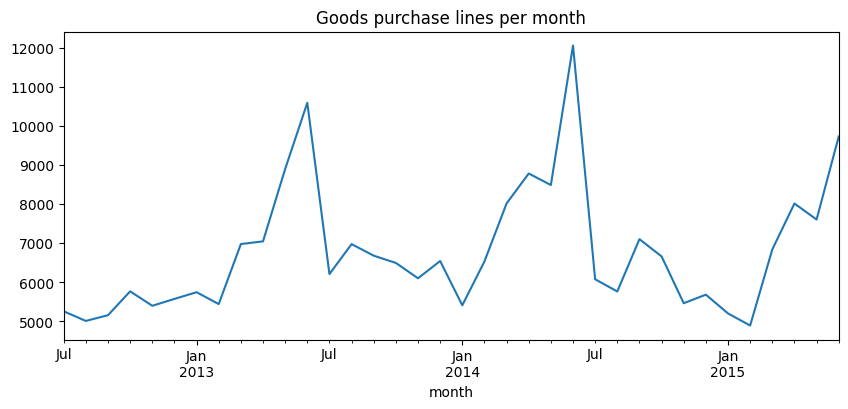

In [2]:
df['lines'].plot(title='Goods purchase lines per month', figsize=(10, 4))
plt.show()

In [3]:
def evaluate(col):
    s = df[col]
    train, test = s[:-12], s[-12:]
    naive = pd.Series(train[-12:].values, index=test.index)
    hw = ExponentialSmoothing(train, trend=None, seasonal='add', seasonal_periods=12).fit()
    pred = hw.forecast(12)
    mape = lambda a, f: (abs(a - f) / a).mean() * 100
    print(col, 'error %: seasonal naive', round(mape(test, naive), 1), '| Holt-Winters', round(mape(test, pred), 1))
    return train, test, naive, pred

for col in ['lines', 'spend']:
    evaluate(col)

lines error %: seasonal naive 13.2 | Holt-Winters 17.0
spend error %: seasonal naive 33.3 | Holt-Winters 21.9


In [4]:
def seasonal_avg(train, test_index):
    by_month = train.groupby(train.index.month).mean()
    return pd.Series([by_month[m] for m in test_index.month], index=test_index)

for col in ['lines', 'spend']:
    s = df[col]
    train, test = s[:-12], s[-12:]
    pred = seasonal_avg(train, test.index)
    print(col, 'seasonal average error %:', round((abs(test - pred) / test).mean() * 100, 1))

lines seasonal average error %: 9.8
spend seasonal average error %: 24.8


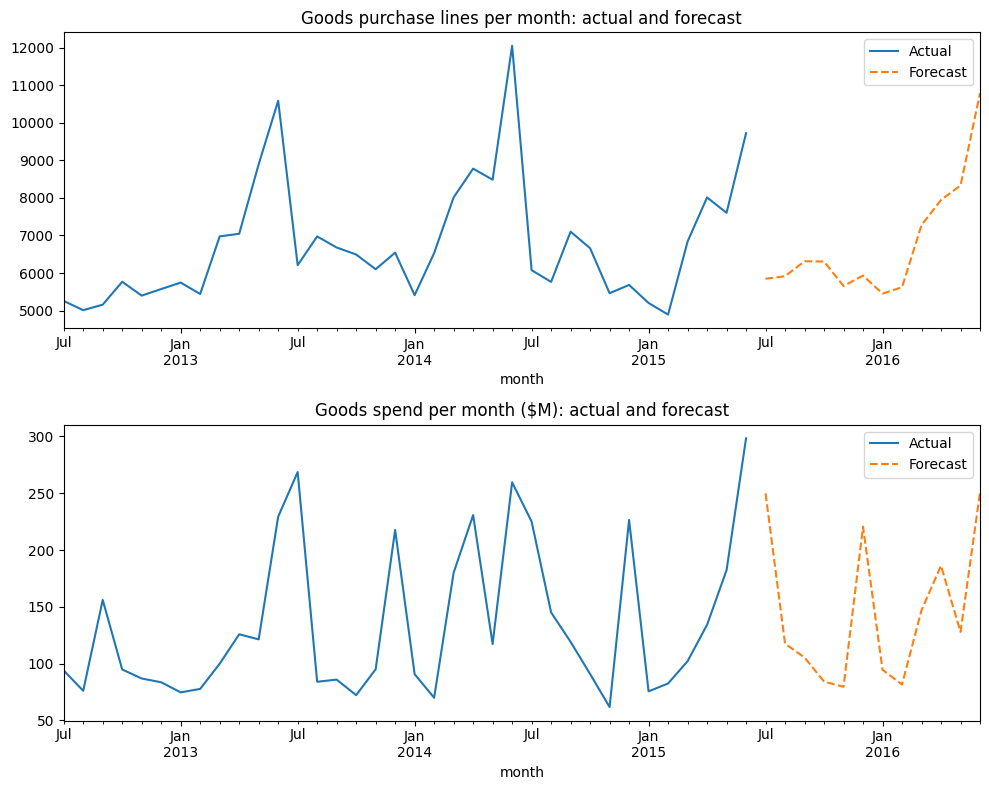

In [5]:
# Lines: average of the same month across past years
lines = df['lines']
future_index = pd.date_range(lines.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq='MS')
by_month = lines.groupby(lines.index.month).mean()
lines_fc = pd.Series([by_month[m] for m in future_index.month], index=future_index, name='lines_forecast')

# Spend: Holt-Winters
spend = df['spend']
spend_fc = ExponentialSmoothing(spend, trend=None, seasonal='add', seasonal_periods=12).fit().forecast(12).rename('spend_forecast')

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
lines.plot(ax=axes[0], label='Actual')
lines_fc.plot(ax=axes[0], label='Forecast', linestyle='--')
axes[0].set_title('Goods purchase lines per month: actual and forecast')
axes[0].legend()
(spend / 1e6).plot(ax=axes[1], label='Actual')
(spend_fc / 1e6).plot(ax=axes[1], label='Forecast', linestyle='--')
axes[1].set_title('Goods spend per month ($M): actual and forecast')
axes[1].legend()
plt.tight_layout()
plt.show()

out = pd.concat([df[['lines', 'spend']], lines_fc, spend_fc], axis=1)
out.to_csv('forecast_goods.csv')

In [6]:
totals = [spend[i:i+12].sum() / 1e9 for i in (0, 12, 24)] + [spend_fc.sum() / 1e9]
print(dict(zip(['FY12-13', 'FY13-14', 'FY14-15', 'FY15-16 forecast'], [round(t, 2) for t in totals])))

{'FY12-13': np.float64(1.32), 'FY13-14': np.float64(1.77), 'FY14-15': np.float64(1.74), 'FY15-16 forecast': np.float64(1.75)}
